# Support Vector Machine

Run `00_prepare_data.ipynb` first. Same train/test split as all other models (seed 42).

In [1]:
import sys
from pathlib import Path

sys.path.insert(0, str(Path("..").resolve() / "src"))

import pandas as pd
from sklearn.metrics import classification_report
from sklearn.model_selection import GridSearchCV, StratifiedKFold
from sklearn.pipeline import Pipeline
from sklearn.svm import SVC

from common import (CLASS_NAMES, SEED, build_preprocessor, get_train_test,
                    plot_confusion_matrix, train_and_evaluate)

## Choosing C and gamma
SVM (RBF kernel) has two main parameters:
- `C`: how strictly the model tries to classify every training point correctly.
- `gamma`: how far the influence of one training point reaches.

To pick them, we try different values with 5-fold cross-validation on the training data only. The test data is not used here. We compare using F1 score, same as KNN and Decision Tree.

`probability=False` during the search makes it faster. The final model uses `probability=True`, which is needed for AUC.

In [2]:
X_train, _, y_train, _ = get_train_test()
pipe = Pipeline([("prep", build_preprocessor(X_train)), ("clf", SVC(kernel="rbf", random_state=SEED))])

grid = GridSearchCV(
    pipe,
    {"clf__C": [0.1, 1, 10, 100], "clf__gamma": ["scale", 0.01, 0.1]},
    scoring="f1",
    cv=StratifiedKFold(5, shuffle=True, random_state=SEED),
    n_jobs=-1,
)
grid.fit(X_train, y_train)

print(grid.best_params_, round(grid.best_score_, 4))
pd.DataFrame(grid.cv_results_)[["param_clf__C", "param_clf__gamma", "mean_test_score", "std_test_score"]] \
    .sort_values("mean_test_score", ascending=False)

{'clf__C': 10, 'clf__gamma': 'scale'} 0.8074


,param_clf__C,param_clf__gamma,mean_test_score,std_test_score
6,10.0,scale,0.807395,0.011521
8,10.0,0.1,0.796731,0.009198
10,100.0,0.01,0.796534,0.016778
11,100.0,0.1,0.792837,0.007233
5,1.0,0.1,0.790408,0.024360
9,100.0,scale,0.783466,0.004409
3,1.0,scale,0.778663,0.018994
7,10.0,0.01,0.771764,0.016811
4,1.0,0.01,0.706715,0.019656
0,0.1,scale,0.615776,0.028394


### Why C = 10, gamma = "scale"
- C=10 with gamma="scale" has the highest F1 (0.8074). The next best is 0.7967 (C=10, gamma=0.1).
- The default setting (C=1, gamma="scale") gives 0.7787, so tuning improves F1 by about 0.03.
- With C=0.1, F1 drops a lot (0.55 to 0.62). The model is too simple and misses many churned customers.
- C=100 does not do better than C=10, so we keep C=10.

## Model

In [3]:
best = {k.replace("clf__", ""): v for k, v in grid.best_params_.items()}
# probability=True needed for AUC
model = SVC(kernel="rbf", probability=True, random_state=SEED, **best)
model

,"C C: float, default=1.0Regularization parameter. The strength of the regularization isinversely proportional to C. Must be strictly positive. The penaltyis a squared l2 penalty. For an intuitive visualization of the effectsof scaling the regularization parameter C, see:ref:`sphx_glr_auto_examples_svm_plot_svm_scale_c.py`.",10
,"probability probability: bool, default=FalseWhether to enable probability estimates. This must be enabled priorto calling `fit`, will slow down that method as it internally uses5-fold cross-validation, and `predict_proba` may be inconsistent with`predict`. Read more in the :ref:`User Guide <scores_probabilities>`...deprecated:: 1.9 The `probability` parameter is deprecated and will be removed in 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`.",True
,"random_state random_state: int, RandomState instance or None, default=NoneControls the pseudo random number generation for shuffling the data forprobability estimates. Ignored when `probability` is False.Pass an int for reproducible output across multiple function calls.See :term:`Glossary <random_state>`.",42
,"kernel kernel: {'linear', 'poly', 'rbf', 'sigmoid', 'precomputed'} or callable, default='rbf'Specifies the kernel type to be used in the algorithm. Ifnone is given, 'rbf' will be used. If a callable is given it is used topre-compute the kernel matrix from data matrices; that matrix should bean array of shape ``(n_samples, n_samples)``. For an intuitivevisualization of different kernel types see:ref:`sphx_glr_auto_examples_svm_plot_svm_kernels.py`.",'rbf'
,"degree degree: int, default=3Degree of the polynomial kernel function ('poly').Must be non-negative. Ignored by all other kernels.",3
,"gamma gamma: {'scale', 'auto'} or float, default='scale'Kernel coefficient for 'rbf', 'poly' and 'sigmoid'.- if ``gamma='scale'`` (default) is passed then it uses 1 / (n_features * X.var()) as value of gamma,- if 'auto', uses 1 / n_features- if float, must be non-negative... versionchanged:: 0.22 The default value of ``gamma`` changed from 'auto' to 'scale'.",'scale'
,"coef0 coef0: float, default=0.0Independent term in kernel function.It is only significant in 'poly' and 'sigmoid'.",0.0
,"shrinking shrinking: bool, default=TrueWhether to use the shrinking heuristic.See the :ref:`User Guide <shrinking_svm>`.",True
,"tol tol: float, default=1e-3Tolerance for stopping criterion.",0.001
,"cache_size cache_size: float, default=200Specify the size of the kernel cache (in MB).",200
,"class_weight class_weight: dict or 'balanced', default=NoneSet the parameter C of class i to class_weight[i]*C forSVC. If not given, all classes are supposed to haveweight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.",None


## Train & evaluate
Saves `model/svm.joblib` and updates `results/metrics.csv`.

In [4]:
result = train_and_evaluate("svm", model)
pd.DataFrame([result["metrics"]], index=["Support Vector Machine"])

C:\Users\user\AppData\Roaming\Python\Python314\site-packages\sklearn\svm\_base.py:236: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(


,Accuracy,AUC,Precision,Recall,F1,MCC
Support Vector Machine,0.9442,0.9657,0.8581,0.7815,0.818,0.7864


## Confusion matrix

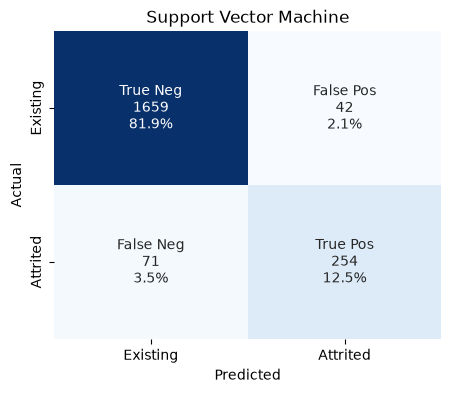

In [5]:
plot_confusion_matrix(result["y_test"], result["y_pred"], title="Support Vector Machine")

## Classification report

In [6]:
print(classification_report(result["y_test"], result["y_pred"], target_names=CLASS_NAMES, digits=4))

              precision    recall  f1-score   support

    Existing     0.9590    0.9753    0.9671      1701
    Attrited     0.8581    0.7815    0.8180       325

    accuracy                         0.9442      2026
   macro avg     0.9085    0.8784    0.8926      2026
weighted avg     0.9428    0.9442    0.9432      2026



## Observations
- SVM has the best scores among all five models: accuracy 0.944, AUC 0.966, F1 0.818, MCC 0.786.
- Recall for churned customers is 0.782, the highest of all models. It finds about 78% of customers who churned.
- Precision (0.858) is close to the best (KNN, 0.863), so SVM finds many more churners without making many more wrong churn predictions.